# Selective prediction with probly

## API Overview

#### Selector

```python
selector(threshold=... | coverage=... | risk=..., delta=...)
```
the rule that decides accept or abstain.

#### Wrap

```python
selective_predictor(model, selector=..., notion=..., loss=..., decider=..., representer_kwargs=...)
```
wraps a model. 
- ``notion`` defaults to total uncertainty, 
- ``loss`` defaults to ``ZeroOneLoss``,
- ``decider`` maps the representation to the decision, defaults to ``categorical_from_mean``,
- ``representer_kwargs``.

#### Calibrate

```python
sp.calibrate(y_cal, X_cal)
```
fits coverage and risk selectors.

#### Predict

```python
sp.predict(x)
```
returns a ``SelectivePrediction`` with ``decision``, ``uncertainty``, ``accepted`` and ``coverage``.

#### Eval

```python
sp.evaluate(y, x)
```
does one forward pass over labeled data and returns a dict of floats (``aurc``, ``augrc``, ``risk@1``, ``risk@1:coverage`` plus ``selected:coverage`` and ``selected:risk`` of the selector). ``metrics=...`` picks others, e.g. ``"risk@0.8"`` or ``"coverage@0.05"``.

## Workflow example

Transforming, training, wrapping a model in ``selective_predictor`` and then calling it.

In [69]:
import torch
from torch import nn
from sklearn.datasets import make_moons

from probly.selective_prediction import selective_predictor, selector
from probly.transformation import dropout

X_train, y_train = make_moons(n_samples=500, noise=0.35, random_state=0)
X_train, y_train = torch.from_numpy(X_train).float(), torch.from_numpy(y_train).long()

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
model = dropout(net, p=0.2, predictor_type="logit_classifier")

opt = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for _ in range(300):
    opt.zero_grad()
    nn.functional.cross_entropy(model(X_train), y_train).backward()
    opt.step()
model.eval()

sp = selective_predictor(model, selector=selector(threshold=0.2), representer_kwargs={"num_samples": 50})

x = torch.tensor([[0.0, 1.0], [0.5, 0.25], [3.0, 2.5]])  # inside a moon, between the moons, far away
with torch.no_grad():
    result = sp.predict(x)

print("prediction ", result.decision.probabilities.argmax(dim=-1).tolist())
print("uncertainty", [round(u, 3) for u in result.uncertainty.tolist()])
print("accepted   ", result.accepted.tolist())
print("coverage   ", result.coverage)

prediction  [0, 1, 0]
uncertainty [0.005, 0.417, 0.233]
accepted    [True, False, False]
coverage    0.3333333333333333


Evaluate the ``selective_predictor``.

In [70]:
X_test, y_test = make_moons(n_samples=500, noise=0.35, random_state=1)
X_test, y_test = torch.from_numpy(X_test).float(), torch.from_numpy(y_test).long()

torch.manual_seed(0)
with torch.no_grad():
    scores = sp.evaluate(y_test, X_test)
print({name: round(value, 3) for name, value in scores.items()})

{'aurc': 0.038, 'augrc': 0.026, 'risk@1': 0.116, 'risk@1:coverage': 1.0, 'selected:coverage': 0.772, 'selected:risk': 0.06}


- ``aurc`` is the area under the risk-coverage curve, so the selective risk averaged over coverage.
- ``augrc`` is the area under the generalized risk, which is the selective risk times the coverage, that is, the loss of the accepted points averaged over all points ("risk of a silent failure"). Better suited for comparing criteria than ``aurc``.

Both areas are threshold-free and lower means better.

- ``risk@1`` is the error rate when nothing is rejected.
- ``risk@1:coverage`` is the coverage actually used.
- ``selected:coverage`` and ``selected:risk`` are the fraction accepted at the chosen threshold, and the error rate on those points. The gap to ``risk@1`` is the benefit of this one threshold.

Risk-coverage curve.

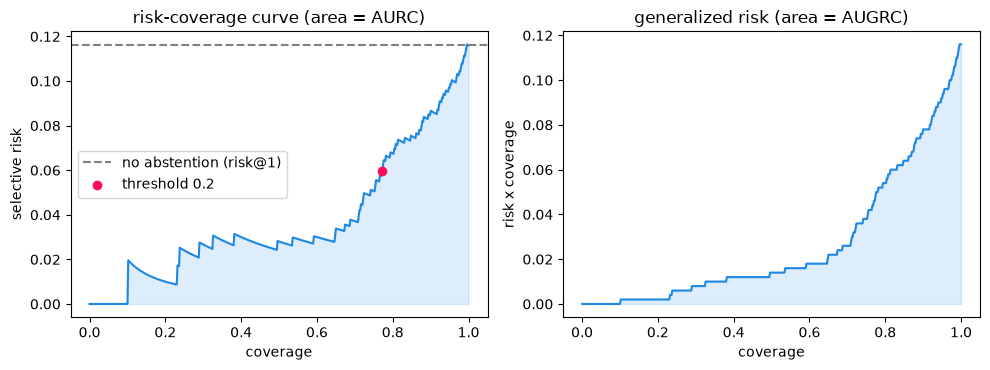

AUGRC from the curve: 0.026 evaluate: 0.026


In [71]:
import matplotlib.pyplot as plt
import numpy as np

from probly.metrics.selective_prediction import risk_coverage_curve

torch.manual_seed(0)  # same MC samples as the evaluate call above
with torch.no_grad():
    test = sp.predict(X_test)
errors = (test.decision.probabilities.argmax(dim=-1) != y_test).float()  # zero-one loss per instance
coverage, risk, _ = risk_coverage_curve(test.uncertainty, errors)
coverage, risk = coverage.numpy(), risk.numpy()

BLUE, RED = "#1e88e5", "#ff0d57"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, curve, title in [
    (axes[0], risk, "risk-coverage curve (area = AURC)"),
    (axes[1], risk * coverage, "generalized risk (area = AUGRC)"),
]:
    ax.plot(coverage, curve, color=BLUE)
    ax.fill_between(coverage, curve, alpha=0.15, color=BLUE)
    ax.set_title(title)
    ax.set_xlabel("coverage")
axes[0].axhline(scores["risk@1"], color="gray", linestyle="--", label="no abstention (risk@1)")
axes[0].scatter(scores["selected:coverage"], scores["selected:risk"], color=RED, zorder=3, label="threshold 0.2")
axes[0].set_ylabel("selective risk")
axes[1].set_ylabel("risk x coverage")
axes[0].legend()
plt.tight_layout()
plt.show()

area = float(np.trapezoid(risk * coverage, coverage))
print("AUGRC from the curve:", round(area, 3), "evaluate:", round(scores["augrc"], 3))

## Regression example

The default ``notion``, ``decider`` and ``loss`` assume a categorical representation. Regression needs a function ``notion``, ``decider`` and ``loss``.

In [72]:
from probly.transformation import ensemble

rng = np.random.default_rng(0)

# 1D data with a gap in the middle, so the model never sees x near 0
X = np.concatenate([rng.uniform(-4.5, -1, 40), rng.uniform(1, 4.5, 40)])
X = torch.from_numpy(X).float().reshape(-1, 1)
y = torch.sin(1.5 * X) + 0.12 * torch.from_numpy(rng.standard_normal(X.shape)).float()

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))
ens = ensemble(net, num_members=10, reset_params=True)

for member in ens:
    opt = torch.optim.Adam(member.parameters(), lr=0.01)
    for _ in range(400):
        opt.zero_grad()
        loss = nn.functional.mse_loss(member(X), y)
        loss.backward()
        opt.step()

In [73]:
def sine_data(n, seed):
    X = torch.linspace(-4.5, 4.5, n).reshape(-1, 1)
    noise = torch.randn(X.shape, generator=torch.Generator().manual_seed(seed))
    return X, (torch.sin(1.5 * X) + 0.12 * noise).squeeze(-1)

# Calibration and test inputs lie on the same grid, so the coverage matches by construction here;
# the guarantee itself is for exchangeable draws.
X_cal, _ = sine_data(300, seed=1)
X_te, y_te = sine_data(400, seed=2)

In [74]:
sp = selective_predictor(
    ens,
    selector=selector(coverage=0.7),
    notion=lambda s: s.sample_var().squeeze(-1),    # criterion, variance across members
    decider=lambda s: s.sample_mean().squeeze(-1),  # decision, ensemble mean
    loss=lambda d, y: (d - y) ** 2,                 # squared error per instance
)

with torch.no_grad():
    sp.calibrate(None, X_cal)
    scores = sp.evaluate(y_te, X_te)
    test = sp.predict(X_te)
print({name: round(value, 3) for name, value in scores.items()})

{'aurc': 0.018, 'augrc': 0.009, 'risk@1': 0.025, 'risk@1:coverage': 1.0, 'selected:coverage': 0.705, 'selected:risk': 0.016}


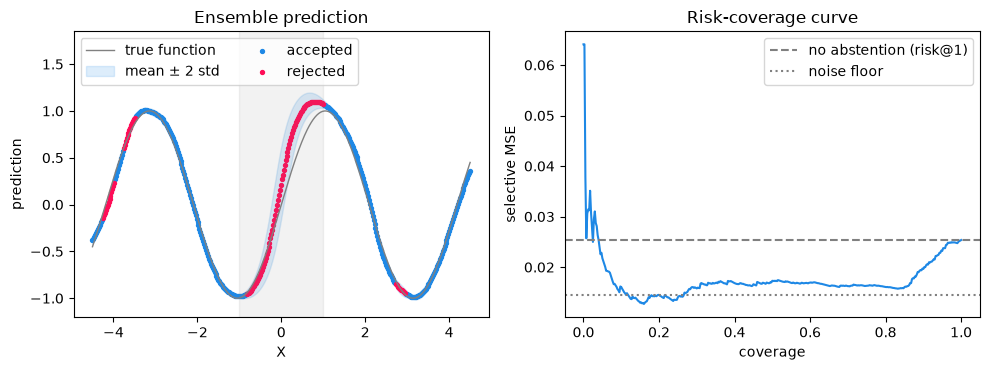

In [75]:
Xs = X_te.squeeze(-1).numpy()
mean = test.decision.numpy()
std = test.uncertainty.sqrt().numpy()  # the criterion, as a standard deviation
accepted = test.accepted.numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

ax = axes[0]
ax.plot(Xs, np.sin(1.5 * Xs), color="gray", lw=1, label="true function")
ax.fill_between(Xs, mean - 2 * std, mean + 2 * std, color=BLUE, alpha=0.15, label=r"mean $\pm$ 2 std")
ax.scatter(Xs[accepted], mean[accepted], s=8, color=BLUE, label="accepted")
ax.scatter(Xs[~accepted], mean[~accepted], s=8, color=RED, label="rejected")
ax.axvspan(-1, 1, color="gray", alpha=0.1)  # the gap without training data
ax.set(xlabel="X", ylabel="prediction", title="Ensemble prediction", ylim=(-1.2, 1.85))
ax.legend(loc="upper left", ncol=2)

ax = axes[1]
errors = (test.decision - y_te) ** 2  # same loss as above
coverage, risk, _ = risk_coverage_curve(test.uncertainty, errors)
ax.plot(coverage.numpy(), risk.numpy(), color=BLUE)
ax.axhline(scores["risk@1"], color="gray", linestyle="--", label="no abstention (risk@1)")
ax.axhline(0.12**2, color="gray", linestyle=":", label="noise floor")  # variance of the label noise
ax.set(xlabel="coverage", ylabel="selective MSE", title="Risk-coverage curve")
ax.legend()
plt.tight_layout()
plt.show()

# Selective prediction on CIFAR-10

In [23]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

from probly.metrics import roc_auc_score, roc_curve
from probly.plot import plot_roc_curve

sys.path.insert(0, "src")  # the experiment package, without installing it
from src.sgr_experiment.data import load_cifar10, normalize
from src.sgr_experiment.loaders import load_base
from src.sgr_experiment.utils import EXPERIMENT_DIR, run_dir

DATA_DIR, RUNS_DIR = EXPERIMENT_DIR / "data", EXPERIMENT_DIR / "runs"

In [24]:
# Helpers for showing data and results; the demos below only call them.
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
CURVE = [f"risk@{c}" for c in np.round(np.arange(0.05, 1.01, 0.05), 2)]  # metrics that trace the risk-coverage curve
TABLE = (1, 0.9, 0.8, 0.7, 0.6, 0.5)  # coverages printed in the table


def show_evaluation(result: dict[str, float], title: str, predictions=None, y: torch.Tensor | None = None) -> None:
    """Print and plot a result of ``SelectivePredictor.evaluate``, whatever metrics were asked for.

    The panels are the classic plots of the metrics: the risk-coverage curve (AURC, with the ``coverage@r`` points as
    dots and the selector as a star), the generalized risk curve (AUGRC) and, given the ``predictions`` on the
    labeled ``y``, the ROC curve of the uncertainty as a detector of wrong predictions (AUROC).
    """
    risk_at = {float(k[5:]): (result[f"{k}:coverage"], v) for k, v in result.items() if k.startswith("risk@") and ":" not in k}
    coverage_at = {k[9:]: (v, result[f"{k}:risk"]) for k, v in result.items() if k.startswith("coverage@") and ":" not in k}
    print("  ".join(f"{k} {result[k]:.4f}" for k in ("aurc", "augrc") if k in result))
    print("risk at coverage  " + "  ".join(f"{c:4.0%}: {risk_at[c][1]:.3f}" for c in TABLE if c in risk_at))
    print("coverage at risk  " + "  ".join(f"{float(r):4.0%}: {cov:.2f}" for r, (cov, _) in coverage_at.items()))
    if "selected:coverage" in result:
        print(f"selector          coverage {result['selected:coverage']:.2f}, risk {result['selected:risk']:.3f}")

    coverage, risk = np.array(sorted(risk_at.values())).T
    fig, axes = plt.subplots(1, 2 if predictions is None else 3, figsize=(14, 3.8))
    axes[0].plot(coverage, risk, ".-")
    axes[0].fill_between(coverage, risk, alpha=0.2)
    for r, (cov, rk) in coverage_at.items():
        axes[0].plot(cov, rk, "o", color="tab:orange")  # NaN, so not drawn, if no coverage meets the risk
        axes[0].annotate(f"coverage@{float(r):.0%}", (cov, rk), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=8)
    if "selected:coverage" in result:
        axes[0].plot(result["selected:coverage"], result["selected:risk"], "*", color="tab:green", ms=14, label="selector")
        axes[0].legend(loc="upper left", fontsize=8)
    axes[1].plot(coverage, coverage * risk, ".-", color="tab:purple")
    axes[1].fill_between(coverage, coverage * risk, color="tab:purple", alpha=0.2)
    axes[0].set(ylabel="selective risk", title=f"AURC {result.get('aurc', np.nan):.4f}")
    axes[1].set(ylabel="generalized risk (coverage x risk)", title=f"AUGRC {result.get('augrc', np.nan):.4f}")
    for ax in axes[:2]:
        ax.set(xlim=(0, 1.02), ylim=(0, None), xlabel="coverage")
    if predictions is not None:
        wrong = (predictions.decision.probabilities.argmax(dim=-1).cpu() != torch.as_tensor(y)).numpy()
        uncertainty = torch.as_tensor(predictions.uncertainty).cpu().numpy()
        fpr, tpr, _ = roc_curve(wrong, uncertainty)
        plot_roc_curve(fpr, tpr, float(roc_auc_score(wrong, uncertainty)), ax=axes[2])
        axes[2].set_title("ROC, uncertainty detecting wrong predictions")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def show_images(x_u8: torch.Tensor, y: torch.Tensor, title: str) -> None:
    """Plot the first 16 uint8 images with their labels."""
    fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
    for ax, image, label in zip(axes.flat, x_u8, y):
        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(CLASSES[int(label)], fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


def show_selective(x_u8: torch.Tensor, y: torch.Tensor, predictions, title: str) -> None:
    """Plot images sorted by uncertainty, framed green if the model answers and red if it abstains.

    A wrong prediction is titled in red with its true class.
    """
    probabilities = predictions.decision.probabilities.cpu()
    decision = probabilities.argmax(dim=-1).numpy()
    uncertainty = torch.as_tensor(predictions.uncertainty).cpu().numpy()
    accepted = torch.as_tensor(predictions.accepted).cpu().numpy()
    wrong = decision != np.asarray(y)

    fig, axes = plt.subplots(len(y) // 8, 8, figsize=(12, 2.1 * (len(y) // 8)))
    for ax, i in zip(axes.flat, np.argsort(uncertainty, kind="stable")):
        ax.imshow(x_u8[i].permute(1, 2, 0).numpy())
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set(color="tab:green" if accepted[i] else "tab:red", linewidth=4)
        label = f"{CLASSES[decision[i]]} ({probabilities[i].max():.0%})" + (f", is {CLASSES[int(y[i])]}" if wrong[i] else "")
        ax.set_title(f"{label}\nunc {uncertainty[i]:.2f}", fontsize=7.5, color="tab:red" if wrong[i] else "black")
    fig.suptitle(f"{title}\naccepted {accepted.sum()} of {len(y)}, wrong among accepted {wrong[accepted].sum()}, "
                 f"wrong among abstained {wrong[~accepted].sum()}", fontsize=10)
    fig.tight_layout()
    plt.show()


## CIFAR-10

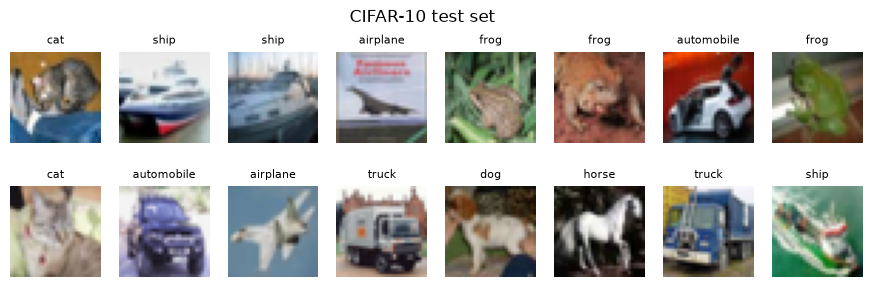

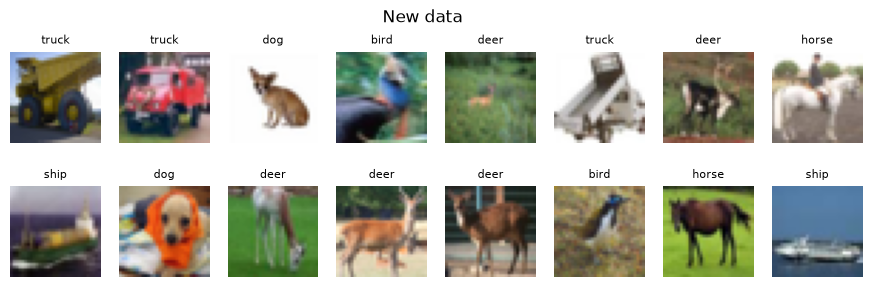

In [25]:
x_test_u8, y_test = load_cifar10(DATA_DIR, train=False)
x_test = normalize(x_test_u8)

# Half of the test set calibrates the selector, the rest evaluates it, and the last 24 images are new data.
perm = np.random.default_rng(0).permutation(len(y_test))
sel_idx, eval_idx, new_idx = perm[:5000], perm[5000:-24], perm[-24:]
x_sel, y_sel = x_test[sel_idx], y_test[sel_idx]
x_eval, y_eval = x_test[eval_idx], y_test[eval_idx]
x_new, y_new, x_new_u8 = x_test[new_idx], y_test[new_idx], x_test_u8[new_idx]

show_images(x_test_u8, y_test, "CIFAR-10 test set")
show_images(x_new_u8, y_new, "New data")

## Trained ensemble

The same predictor as `ensemble(model, ...)` in the demo, but with the five trained seeds (`runs/seed0` to
`runs/seed4`) as members instead of re-initialized copies.

In [26]:
from probly.method import ensemble

trained_ensemble = ensemble(
    load_base(run_dir(RUNS_DIR, seed=0) / "base.pt", arch="vgg16"), num_members=5, predictor_type="logit_classifier"
)
for seed, member in enumerate(trained_ensemble):
    member.load_state_dict(load_base(run_dir(RUNS_DIR, seed=seed) / "base.pt", arch="vgg16").state_dict())
    member.eval()

## Demo

aurc 0.0056  augrc 0.0041
risk at coverage  100%: 0.050   90%: 0.015   80%: 0.005   70%: 0.002   60%: 0.001   50%: 0.000
coverage at risk    1%: 0.86    3%: 0.96
selector          coverage 0.81, risk 0.005


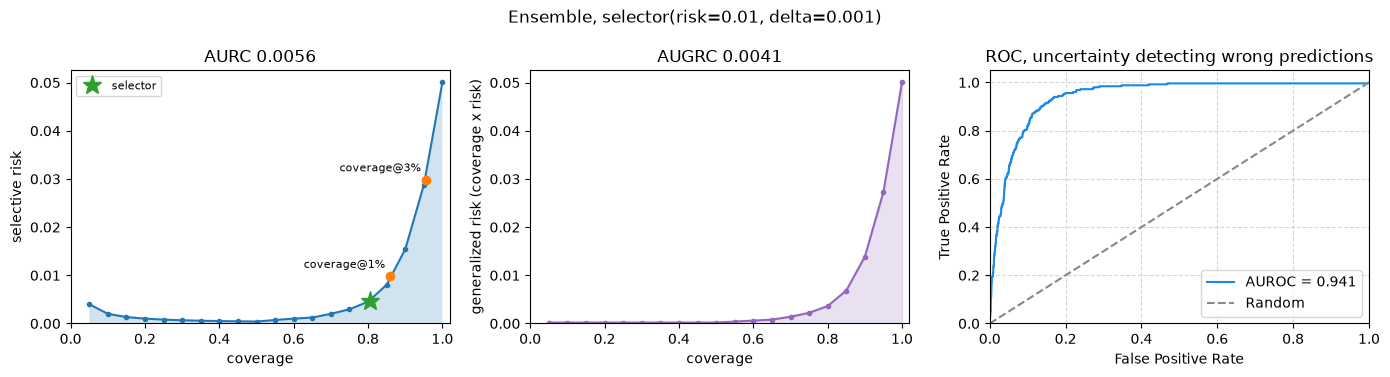

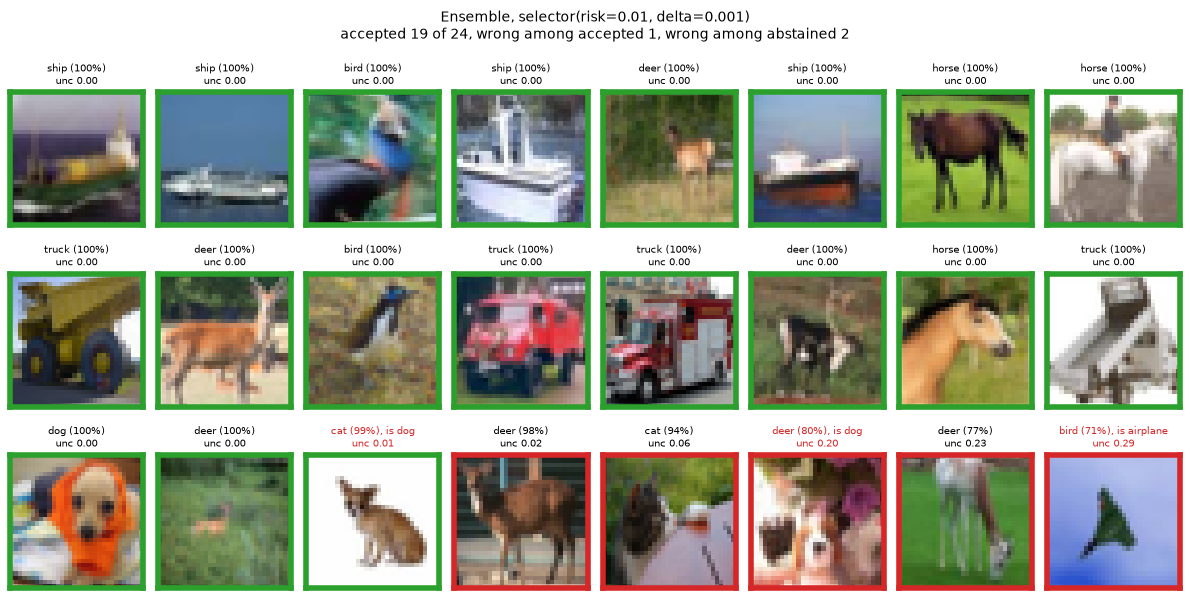

In [29]:
from probly.method import ensemble
from probly.selective_prediction import selector, selective_predictor

model = load_base(run_dir(RUNS_DIR, seed=0) / "base.pt", arch="vgg16")

# Make the model uncertainty-aware; the trained ensemble then replaces the untrained one.
ensemble_model = ensemble(model, num_members=5, reset_params=True, predictor_type="logit_classifier")
ensemble_model = trained_ensemble

# Accept as many images as possible with at most 1% errors among them.
selective_model = selective_predictor(ensemble_model, selector=selector(risk=0.01, delta=0.001))

with torch.no_grad():
    selective_model.calibrate(y_sel, x_sel)
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    evaluation = selective_model.predict(x_eval)
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Ensemble, {selective_model.selector}", evaluation, y_eval)
show_selective(x_new_u8, y_new, predictions, title=f"Ensemble, {selective_model.selector}")

aurc 0.0077  augrc 0.0066
risk at coverage  100%: 0.064   90%: 0.025   80%: 0.010   70%: 0.005   60%: 0.003   50%: 0.002
coverage at risk    1%: 0.81    3%: 0.92
selector          coverage 0.81, risk 0.010


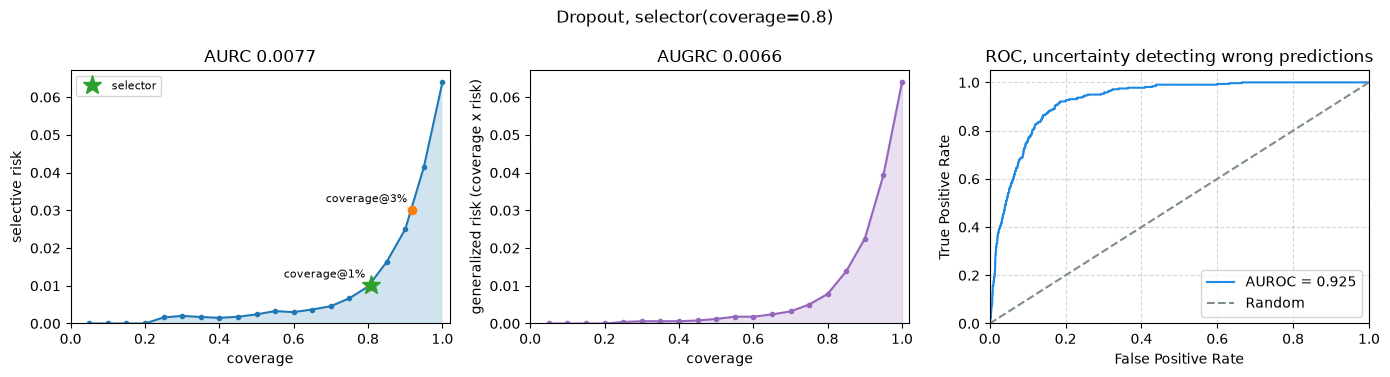

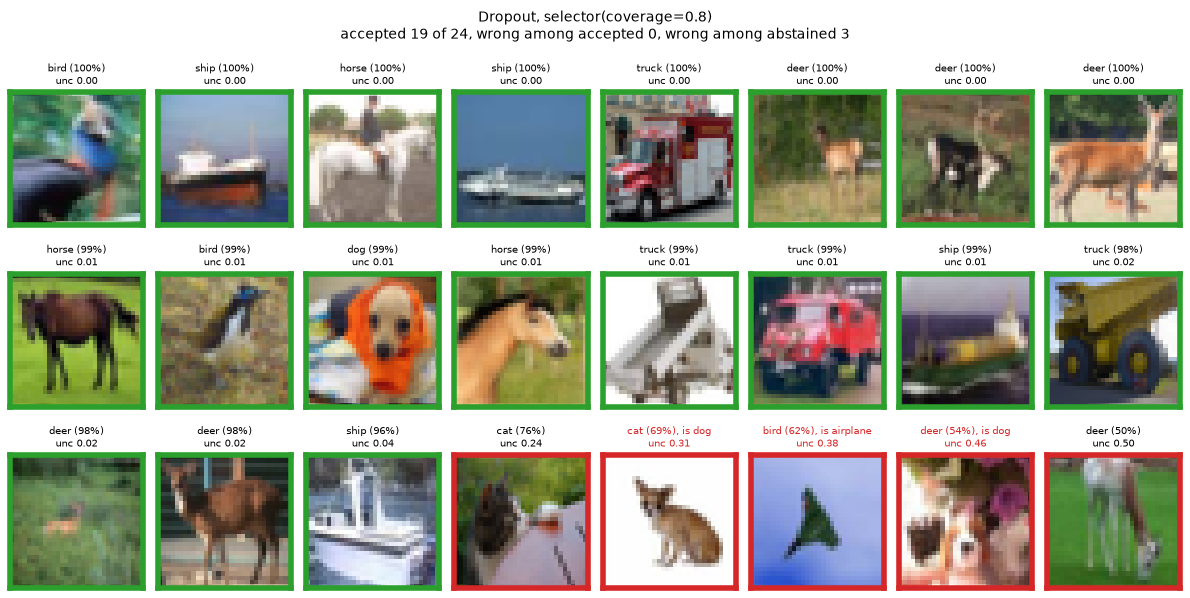

In [31]:
from probly.method import dropout

dropout_model = dropout(model, p=0.5, predictor_type="logit_classifier")

# Accept the 80% most certain images.
selective_model = selective_predictor(
    dropout_model, selector=selector(coverage=0.8), representer_kwargs={"num_samples": 5}
)

with torch.no_grad():
    selective_model.calibrate(None, x_sel)
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    evaluation = selective_model.predict(x_eval)
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Dropout, {selective_model.selector}", evaluation, y_eval)
show_selective(x_new_u8, y_new, predictions, title=f"Dropout, {selective_model.selector}")

aurc 0.0092  augrc 0.0072
risk at coverage  100%: 0.065   90%: 0.027   80%: 0.012   70%: 0.007   60%: 0.004   50%: 0.002
coverage at risk    1%: 0.78    3%: 0.91
selector          coverage 0.98, risk 0.056


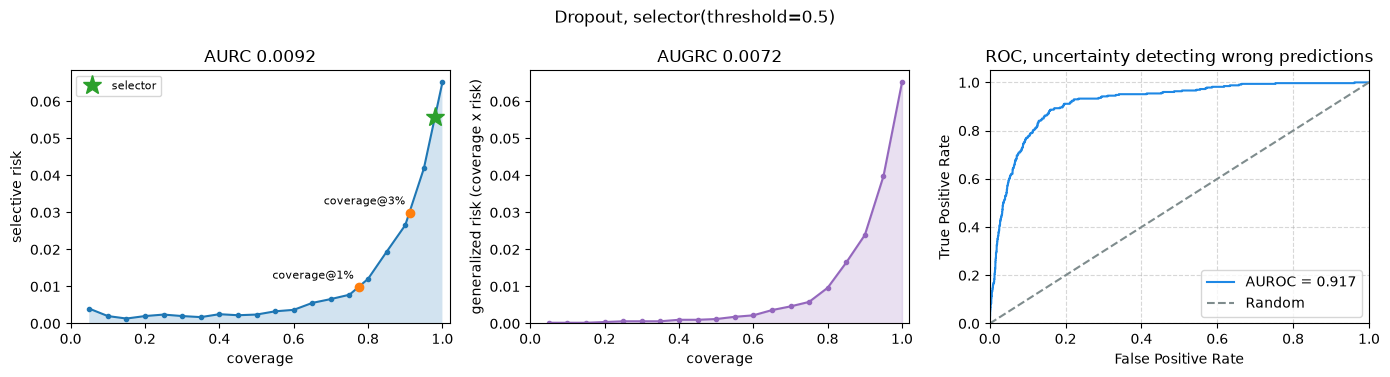

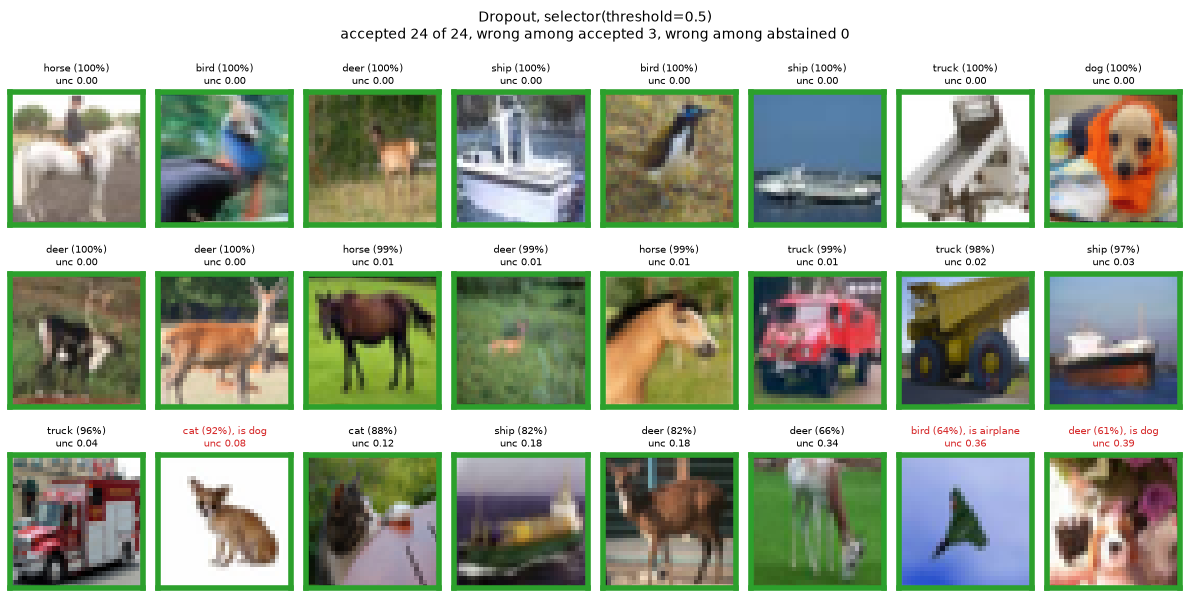

In [33]:
# Accept every image with an uncertainty below 0.5; a fixed threshold needs no calibration.
selective_model = selective_predictor(
    dropout_model, selector=selector(threshold=0.5), representer_kwargs={"num_samples": 5}
)

with torch.no_grad():
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    evaluation = selective_model.predict(x_eval)
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Dropout, {selective_model.selector}", evaluation, y_eval)
show_selective(x_new_u8, y_new, predictions, title=f"Dropout, {selective_model.selector}")